<a href="https://colab.research.google.com/github/Shivangi-Shah-beep/crossview-masked-image-reconstruction/blob/main/NVSAutoEncoder.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os, re, glob, shutil, subprocess
import numpy as np
import pandas as pd
import torch
import cv2
from PIL import Image
from tqdm import tqdm

# where things go
DRIVE_ROOT = "/content/drive/MyDrive/datasets"   # pair CSVs and caches, kept
LOCAL_ROOT = "/content/data"                     # raw downloads, local disk only, wiped on reset
TMP_DIR = "/content/tmp"                         # zips, deleted after extraction
DELETE_RAW_AFTER = True                          # delete raw frames once a room/video is done

IMG = 128                                        # cache resolution
SIFT_W, SIFT_H = 640, 480                        # every frame is resized to this for SIFT (all datasets are 4:3)

# ---------------- 7-Scenes ----------------
SEVEN_SCENES = ["office", "redkitchen", "chess", "pumpkin", "fire", "stairs"]
SEVEN_URL = "http://download.microsoft.com/download/2/8/5/28564B23-0828-408F-8631-23B1EFF1DAC8"
SEVEN_STRIDE = 5
SEVEN_K = np.array([[585.0, 0, 320.0], [0, 585.0, 240.0], [0, 0, 1]])   # 640x480, no calibration file

# ---------------- 12-Scenes ----------------
TWELVE_ROOMS = {
    "apt1": ["kitchen", "living"],
    "apt2": ["bed", "kitchen", "living", "luke"],
    "office1": ["gates362", "gates381", "lounge", "manolis"],
    "office2": ["5a", "5b"],
}
TWELVE_URL = "http://graphics.stanford.edu/projects/reloc/data"
TWELVE_STRIDE = 5

# ---------------- ARKitScenes ----------------
ARKIT_URL = "https://docs-assets.developer.apple.com/ml-research/datasets/arkitscenes/v1"
ARKIT_SPLITS_CSV = "https://raw.githubusercontent.com/apple/ARKitScenes/main/raw/raw_train_val_splits.csv"
ARKIT_N_TRAIN = 100      # videos from the Training fold, one per room
ARKIT_N_TEST = 20        # videos from the Validation fold, used as test (rooms never trained on)
ARKIT_MIN_DT = 0.5       # seconds between kept frames
ARKIT_DEPTH = True       # also download lidar depth (roughly doubles the download)
ARKIT_SEED = 0

DATASETS = {
    "7scenes": {"tag": f"s{SEVEN_STRIDE}"},
    "12scenes": {"tag": f"s{TWELVE_STRIDE}"},
    "arkitscenes": {"tag": f"dt{int(round(ARKIT_MIN_DT * 1000))}"},
}
for name, d in DATASETS.items():
    d["pair_dir"] = f"{DRIVE_ROOT}/{name}/pairs"
    d["cache_dir"] = f"{DRIVE_ROOT}/{name}/cache"
    for p in (d["pair_dir"], d["cache_dir"]):
        os.makedirs(p, exist_ok=True)
for p in (LOCAL_ROOT, TMP_DIR):
    os.makedirs(p, exist_ok=True)

def pair_csv(dataset, unit, split):
    d = DATASETS[dataset]
    return os.path.join(d["pair_dir"], f"{unit}_{d['tag']}_{split}_pairs_sift.csv")

def cache_path(dataset, unit, split):
    d = DATASETS[dataset]
    return os.path.join(d["cache_dir"], f"{unit}_{d['tag']}_{split}_{IMG}.npz")

def read_pair_csv(path):
    return pd.read_csv(path, dtype={"seq_a": str, "seq_b": str})

def is_done(dataset, unit, split):
    """CSV and cache in Drive, or an empty CSV (nothing usable, no cache needed)."""
    csv = pair_csv(dataset, unit, split)
    if not os.path.exists(csv):
        return False
    return os.path.exists(cache_path(dataset, unit, split)) or len(read_pair_csv(csv)) == 0

# cheap pose prefilter
MAX_CENTER_DIST = 2.5      # meters
MAX_VIEW_ANGLE = 90.0      # degrees

# SIFT overlap
SIFT_FEATURES = 1500
RATIO = 0.8                # ratio test threshold
RANSAC_THRESH = 1.5        # pixels
MIN_INLIERS = 30           # fewer verified matches than this = no overlap
GRID = 8                   # 8x8 cells for measuring overlap
MIN_KP_CELLS = 16          # frames with keypoints in fewer cells are skipped (blank views)
SIFT_MIN_KEEP = 0.3        # save pairs at or above this
OV_LO, OV_HI = 0.5, 0.8    # training range (only used for the summary here)

device = "cuda" if torch.cuda.is_available() else "cpu"
RANSAC_METHOD = getattr(cv2, "USAC_MAGSAC", cv2.FM_RANSAC)
sift = cv2.SIFT_create(nfeatures=SIFT_FEATURES)

def free_gb(path="/content"):
    return shutil.disk_usage(path).free / 1e9

print(f"device: {device} | local disk free: {free_gb():.0f} GB")

device: cuda | local disk free: 208 GB


In [ ]:
def run(cmd, ok=(0,)):
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode not in ok:
        raise RuntimeError(f"{' '.join(cmd)} failed (exit {r.returncode}):\n{(r.stderr + r.stdout)[-2000:]}")

def download(url, path, progress=False):
    """Resumable download into path. Returns False if it fails (for example the file does not exist)."""
    if os.path.exists(path):
        return True
    part = path + ".part"
    cmd = ["wget", "-c", "-q", url, "-O", part] + (["--show-progress"] if progress else [])
    r = subprocess.run(cmd, capture_output=not progress, text=True)
    if r.returncode != 0:
        if os.path.exists(part) and os.path.getsize(part) == 0:
            os.remove(part)
        return False
    os.rename(part, path)
    return True

def extract(zip_path, dst):
    run(["unzip", "-q", "-o", zip_path, "-d", dst], ok=(0, 1))   # exit 1 = finished with warnings
    os.remove(zip_path)

def read_pose_txt(path):
    """4x4 camera-to-world, or None if missing or invalid (bad frames contain inf/INF)."""
    try:
        T = np.loadtxt(path)
    except (OSError, ValueError):
        return None
    if T.shape != (4, 4) or not np.all(np.isfinite(T)):
        return None
    return T

def nearest(sorted_vals, x):
    i = int(np.searchsorted(sorted_vals, x))
    cands = [j for j in (i - 1, i) if 0 <= j < len(sorted_vals)]
    return min(cands, key=lambda j: abs(sorted_vals[j] - x))

# Every frame is a dict: seq, idx (int), color path, depth path, pose (4x4 camera-to-world),
# K (3x3 at the image's own size), w, h

# ---------------- 7-Scenes ----------------
def prepare_7scenes(scene):
    root = os.path.join(LOCAL_ROOT, "7scenes")
    scene_dir = os.path.join(root, scene)
    if not os.path.exists(os.path.join(scene_dir, "TrainSplit.txt")):
        zip_path = os.path.join(TMP_DIR, f"7scenes_{scene}.zip")
        print(f"7scenes {scene}: downloading ({free_gb():.0f} GB free locally)")
        if not download(f"{SEVEN_URL}/{scene}.zip", zip_path, progress=True):
            raise RuntimeError(f"7scenes {scene}: download failed")
        extract(zip_path, root)
    for seq_zip in sorted(glob.glob(os.path.join(scene_dir, "seq-*.zip"))):
        print(f"7scenes {scene}: extracting {os.path.basename(seq_zip)}")
        extract(seq_zip, scene_dir)
    return scene_dir

def read_split_7(scene_dir, name):
    with open(os.path.join(scene_dir, name)) as f:
        ids = [int(l.strip().replace("sequence", "")) for l in f if l.strip()]
    return [f"seq-{i:02d}" for i in ids]

def frames_7scenes(scene_dir, seqs):
    frames = []
    for seq in seqs:
        n = len(glob.glob(os.path.join(scene_dir, seq, "*.color.png")))
        for idx in range(0, n, SEVEN_STRIDE):
            base = os.path.join(scene_dir, seq, f"frame-{idx:06d}")
            pose = read_pose_txt(base + ".pose.txt")
            if pose is None:
                continue
            frames.append(dict(seq=seq, idx=idx, color=base + ".color.png", depth=base + ".depth.png",
                               pose=pose, K=SEVEN_K, w=640, h=480))
    return frames

# ---------------- 12-Scenes ----------------
def prepare_12scenes(apt):
    root = os.path.join(LOCAL_ROOT, "12scenes")
    apt_dir = os.path.join(root, apt)
    marker = os.path.join(apt_dir, ".extracted")
    if not os.path.exists(marker):
        zip_path = os.path.join(TMP_DIR, f"12scenes_{apt}.zip")
        print(f"12scenes {apt}: downloading ({free_gb():.0f} GB free locally)")
        if not download(f"{TWELVE_URL}/{apt}.zip", zip_path, progress=True):
            raise RuntimeError(f"12scenes {apt}: download failed")
        print(f"12scenes {apt}: extracting")
        extract(zip_path, root)
        if not os.path.isdir(apt_dir):
            raise RuntimeError(f"expected {apt_dir} after unzip, found: {sorted(os.listdir(root))}")
        open(marker, "w").close()
    return apt_dir

def frames_12scenes(room_dir, split):
    if not os.path.isdir(room_dir):
        raise RuntimeError(f"{room_dir} not found. Rooms present: {sorted(os.listdir(os.path.dirname(room_dir)))}")
    with open(os.path.join(room_dir, "split.txt")) as f:
        n_test = int(re.search(r"frames=(\d+)", f.readline()).group(1))   # first n_test frames = test set
    info = {}
    with open(os.path.join(room_dir, "info.txt")) as f:
        for line in f:
            if "=" in line:
                k, v = line.split("=", 1)
                info[k.strip()] = v.strip()
    K = np.array(info["m_calibrationColorIntrinsic"].split(), dtype=np.float64).reshape(4, 4)[:3, :3]
    colors = sorted(glob.glob(os.path.join(room_dir, "data", "frame-*.color.jpg")))
    h, w = cv2.imread(colors[0]).shape[:2]
    K[0] *= w / float(info.get("m_colorWidth", w))       # in case the images are not at the info.txt size
    K[1] *= h / float(info.get("m_colorHeight", h))

    frames = []
    for c in colors:
        idx = int(os.path.basename(c)[6:12])              # frame-000123.color.jpg
        if (idx < n_test) != (split == "test") or idx % TWELVE_STRIDE:
            continue
        base = c[: -len(".color.jpg")]
        pose = read_pose_txt(base + ".pose.txt")
        if pose is None:
            continue
        frames.append(dict(seq="seq-01", idx=idx, color=c, depth=base + ".depth.png",
                           pose=pose, K=K, w=w, h=h))
    return frames

# ---------------- ARKitScenes ----------------
def arkit_video_list():
    """{video_id: (fold, split)}: one video per room, a fixed random subset of each fold."""
    df = pd.read_csv(ARKIT_SPLITS_CSV, dtype={"video_id": str, "visit_id": str})
    df["visit_id"] = df["visit_id"].fillna(df["video_id"])        # missing visit id: treat the video as its own room
    rng = np.random.default_rng(ARKIT_SEED)
    out = {}
    for fold, split, n in [("Training", "train", ARKIT_N_TRAIN), ("Validation", "test", ARKIT_N_TEST)]:
        rooms = df[df.fold == fold].groupby("visit_id", sort=True).first().reset_index()
        pick = rooms.iloc[rng.permutation(len(rooms))[:n]]          # same seed: raising n only adds videos
        out.update({v: (fold, split) for v in pick.video_id})
    return out

def prepare_arkit(video_id, fold):
    """Download traj, frames, intrinsics (and depth). Returns the folder, or None if something is missing."""
    vdir = os.path.join(LOCAL_ROOT, "arkitscenes", video_id)
    os.makedirs(vdir, exist_ok=True)
    base = f"{ARKIT_URL}/raw/{fold}/{video_id}"
    if not download(f"{base}/lowres_wide.traj", os.path.join(vdir, "lowres_wide.traj")):
        return None
    assets = ["lowres_wide", "lowres_wide_intrinsics"] + (["lowres_depth"] if ARKIT_DEPTH else [])
    for a in assets:
        done = os.path.join(vdir, f".{a}_done")
        if os.path.exists(done):
            continue
        zp = os.path.join(TMP_DIR, f"{video_id}_{a}.zip")
        if not download(f"{base}/{a}.zip", zp):
            if a == "lowres_depth":
                continue                                            # depth is optional
            return None
        extract(zp, vdir)
        if not os.path.isdir(os.path.join(vdir, a)):
            raise RuntimeError(f"{a}.zip did not create {a}/ in {vdir}: {os.listdir(vdir)}")
        open(done, "w").close()
    return vdir

def frames_arkit(vdir, video_id):
    traj = np.loadtxt(os.path.join(vdir, "lowres_wide.traj"), ndmin=2)   # ts, axis-angle (3), translation (3)
    traj = traj[np.argsort(traj[:, 0])]
    t_ts = traj[:, 0]

    pins = {}
    for p in glob.glob(os.path.join(vdir, "lowres_wide_intrinsics", "*.pincam")):
        pins[float(os.path.basename(p)[:-len(".pincam")].split("_", 1)[1])] = p
    pin_ts = np.array(sorted(pins))
    if len(t_ts) == 0 or len(pin_ts) == 0:
        return []

    def ts_of(path):
        return float(os.path.basename(path)[:-4].split("_", 1)[1])   # <video_id>_<timestamp>.png

    frames, last = [], -1e9
    for c in sorted(glob.glob(os.path.join(vdir, "lowres_wide", "*.png")), key=ts_of):
        ts = ts_of(c)
        if ts - last < ARKIT_MIN_DT:
            continue
        j, k = nearest(t_ts, ts), nearest(pin_ts, ts)
        if abs(t_ts[j] - ts) > 0.005 or abs(pin_ts[k] - ts) > 0.005:
            continue                                                # no pose or intrinsics for this frame
        w, h, fx, fy, cx, cy = np.loadtxt(pins[pin_ts[k]])
        R, _ = cv2.Rodrigues(traj[j, 1:4])
        w2c = np.eye(4)
        w2c[:3, :3], w2c[:3, 3] = R, traj[j, 4:7]
        frames.append(dict(seq=video_id, idx=int(round(ts * 1000)), color=c,
                           depth=os.path.join(vdir, "lowres_depth", os.path.basename(c)),
                           pose=np.linalg.inv(w2c),                 # traj stores world-to-camera
                           K=np.array([[fx, 0, cx], [0, fy, cy], [0, 0, 1]]), w=int(w), h=int(h)))
        last = ts
    return frames

In [ ]:
def sift_features(path):
    empty = (np.zeros((0, 2), np.float32), np.zeros((0, 128), np.float32))
    gray = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if gray is None:
        return empty
    if gray.shape[:2] != (SIFT_H, SIFT_W):
        interp = cv2.INTER_AREA if gray.shape[1] > SIFT_W else cv2.INTER_LINEAR
        gray = cv2.resize(gray, (SIFT_W, SIFT_H), interpolation=interp)
    kps, desc = sift.detectAndCompute(gray, None)
    if desc is None or len(kps) < 2:
        return empty
    xy = np.array([k.pt for k in kps], dtype=np.float32)
    desc = desc / (desc.sum(axis=1, keepdims=True) + 1e-8)   # RootSIFT: L1 normalize
    desc = np.sqrt(desc)                                       # then sqrt, now unit length
    return xy, desc.astype(np.float32)

def cell_ids(xy):
    cx = np.clip((xy[:, 0] / SIFT_W * GRID).astype(int), 0, GRID - 1)
    cy = np.clip((xy[:, 1] / SIFT_H * GRID).astype(int), 0, GRID - 1)
    return cy * GRID + cx

def load_features(frames, label):
    xys, descs, cells, n_cells = [], [], [], []
    for f in tqdm(frames, desc=f"SIFT {label}"):
        xy, desc = sift_features(f["color"])
        c = cell_ids(xy) if len(xy) else np.zeros(0, int)
        xys.append(xy)
        descs.append(torch.from_numpy(desc).to(device))
        cells.append(c)
        n_cells.append(len(np.unique(c)))
    poses = torch.from_numpy(np.stack([f["pose"] for f in frames])).float().to(device)
    return poses, xys, descs, cells, np.array(n_cells)

def match_pair(da, db):
    """Mutual nearest neighbors that pass the ratio test. Returns index arrays into A and B."""
    if len(da) < 2 or len(db) < 2:
        return None, None
    sim = da @ db.T
    dist = torch.sqrt(torch.clamp(2 - 2 * sim, min=0))
    top2 = torch.topk(dist, 2, dim=1, largest=False)
    nn_ab = top2.indices[:, 0]
    ratio_ok = top2.values[:, 0] < RATIO * top2.values[:, 1]
    nn_ba = torch.argmin(dist, dim=0)
    mutual = nn_ba[nn_ab] == torch.arange(len(da), device=da.device)
    ia = torch.nonzero(ratio_ok & mutual).squeeze(1)
    ib = nn_ab[ia]
    return ia.cpu().numpy(), ib.cpu().numpy()

def sift_overlap(i, j, xys, descs, cells, n_cells):
    """Returns (overlap, ov_a, ov_b, n_inliers)."""
    empty = (0.0, 0.0, 0.0, 0)
    if n_cells[i] < MIN_KP_CELLS or n_cells[j] < MIN_KP_CELLS:
        return empty
    ia, ib = match_pair(descs[i], descs[j])
    if ia is None or len(ia) < MIN_INLIERS:
        return empty
    pa, pb = xys[i][ia], xys[j][ib]
    mask = None
    for method in (RANSAC_METHOD, cv2.FM_RANSAC):
        try:
            _, mask = cv2.findFundamentalMat(pa, pb, method, RANSAC_THRESH, 0.999, 10000)
        except cv2.error:
            mask = None
        if mask is not None:
            break
    if mask is None:
        return empty
    inl = mask.ravel().astype(bool)
    if inl.sum() < MIN_INLIERS:
        return empty
    ia, ib = ia[inl], ib[inl]
    ov_a = len(np.unique(cells[i][ia])) / n_cells[i]
    ov_b = len(np.unique(cells[j][ib])) / n_cells[j]
    return min(ov_a, ov_b), ov_a, ov_b, int(inl.sum())

PAIR_COLS = ["scene", "split", "seq_a", "idx_a", "seq_b", "idx_b", "overlap", "ov_a", "ov_b",
             "inliers", "dist_m", "angle_deg", "same_seq"]

def build_pairs_sift(unit, split_name, frames):
    if len(frames) < 2:
        return pd.DataFrame(columns=PAIR_COLS)
    poses, xys, descs, cells, n_cells = load_features(frames, f"{unit} {split_name}")

    centers = poses[:, :3, 3]
    fwd = poses[:, :3, 2]
    dist = torch.cdist(centers, centers)
    angle = torch.rad2deg(torch.acos((fwd @ fwd.T).clamp(-1, 1)))
    cand = (dist < MAX_CENTER_DIST) & (angle < MAX_VIEW_ANGLE)
    iu, ju = torch.nonzero(torch.triu(cand, diagonal=1), as_tuple=True)
    iu, ju = iu.cpu().numpy(), ju.cpu().numpy()
    dist, angle = dist.cpu().numpy(), angle.cpu().numpy()
    print(f"{unit} {split_name}: {len(frames)} frames, {len(iu)} pairs to match")

    rows = []
    for i, j in tqdm(zip(iu, ju), total=len(iu), desc=f"match {unit} {split_name}"):
        ov, ov_a, ov_b, n_in = sift_overlap(i, j, xys, descs, cells, n_cells)
        if ov >= SIFT_MIN_KEEP:
            fa, fb = frames[i], frames[j]
            rows.append([unit, split_name, fa["seq"], fa["idx"], fb["seq"], fb["idx"], ov, ov_a, ov_b, n_in,
                         dist[i, j], angle[i, j], fa["seq"] == fb["seq"]])

    del descs, poses                          # free GPU memory before the next split
    if device == "cuda":
        torch.cuda.empty_cache()
    return pd.DataFrame(rows, columns=PAIR_COLS)

In [ ]:
def build_cache(dataset, unit, split, frames, df):
    """Cache every frame used by a saved pair: 128px color, 128px depth, pose, intrinsics at 128px."""
    path = cache_path(dataset, unit, split)
    if os.path.exists(path):
        return
    used = set(zip(df.seq_a.astype(str), df.idx_a.astype(int))) | set(zip(df.seq_b.astype(str), df.idx_b.astype(int)))
    keep = [f for f in frames if (str(f["seq"]), int(f["idx"])) in used]
    N = len(keep)
    images = np.zeros((N, IMG, IMG, 3), dtype=np.uint8)
    depths = np.zeros((N, IMG, IMG), dtype=np.uint16)        # millimeters, 0 or 65535 = invalid
    poses = np.zeros((N, 4, 4), dtype=np.float32)            # camera-to-world
    Ks = np.zeros((N, 3, 3), dtype=np.float32)               # intrinsics for the 128x128 image
    for n, f in enumerate(tqdm(keep, desc=f"cache {unit} {split}")):
        img = Image.open(f["color"]).convert("RGB")
        images[n] = np.array(img.resize((IMG, IMG), Image.BILINEAR))
        if os.path.exists(f["depth"]):
            d = cv2.imread(f["depth"], cv2.IMREAD_UNCHANGED)
            if d is not None:
                depths[n] = cv2.resize(d, (IMG, IMG), interpolation=cv2.INTER_NEAREST)   # never blend depths
        poses[n] = f["pose"]
        K = f["K"].astype(np.float32).copy()
        K[0] *= IMG / f["w"]                                  # fx, cx
        K[1] *= IMG / f["h"]                                  # fy, cy
        Ks[n] = K
    np.savez_compressed(path, images=images, depths=depths, poses=poses, Ks=Ks,
                        seqs=np.array([str(f["seq"]) for f in keep]),
                        idxs=np.array([int(f["idx"]) for f in keep]))
    print(f"saved {N} frames to {path} ({os.path.getsize(path) / 1e6:.0f} MB)")

In [ ]:
summary = []

def record(dataset, unit, split):
    df = read_pair_csv(pair_csv(dataset, unit, split))
    n_range = int(df.overlap.between(OV_LO, OV_HI).sum()) if len(df) else 0
    summary.append((dataset, unit, split, len(df), n_range))

def process_unit(dataset, unit, split, get_frames):
    """get_frames is only called if work is left, so finished units never download anything."""
    if is_done(dataset, unit, split):
        print(f"{dataset} {unit} {split}: already in Drive, skipping")
    else:
        frames = get_frames()
        csv = pair_csv(dataset, unit, split)
        if os.path.exists(csv):
            df = read_pair_csv(csv)
        else:
            df = build_pairs_sift(unit, split, frames)
            df.to_csv(csv, index=False)               # saved right away, survives a disconnect
            print(f"saved {csv} ({len(df)} pairs)")
        if len(df):
            build_cache(dataset, unit, split, frames, df)
    record(dataset, unit, split)

def cleanup(path):
    if DELETE_RAW_AFTER and path and os.path.isdir(path):
        shutil.rmtree(path)
        print(f"deleted {path} | local disk free: {free_gb():.0f} GB")

# ---------------- 7-Scenes ----------------
for scene in SEVEN_SCENES:
    state = {}
    def scene_dir():
        if "dir" not in state:
            state["dir"] = prepare_7scenes(scene)
        return state["dir"]
    for split, split_file in [("train", "TrainSplit.txt"), ("test", "TestSplit.txt")]:
        process_unit("7scenes", scene, split,
                     lambda: frames_7scenes(scene_dir(), read_split_7(scene_dir(), split_file)))
    cleanup(state.get("dir"))

# ---------------- 12-Scenes ----------------
for apt, rooms in TWELVE_ROOMS.items():
    state = {}
    def apt_dir():
        if "dir" not in state:
            state["dir"] = prepare_12scenes(apt)
        return state["dir"]
    for room in rooms:
        for split in ("train", "test"):
            process_unit("12scenes", f"{apt}_{room}", split,
                         lambda: frames_12scenes(os.path.join(apt_dir(), room), split))
    cleanup(state.get("dir"))

# ---------------- ARKitScenes ----------------
videos = arkit_video_list()
print(f"ARKitScenes: {sum(s == 'train' for _, s in videos.values())} train videos, "
      f"{sum(s == 'test' for _, s in videos.values())} test videos selected")
for vid, (fold, split) in videos.items():
    state = {}
    def get_frames():
        state["dir"] = prepare_arkit(vid, fold)
        if state["dir"] is None:
            print(f"arkitscenes {vid}: missing files, skipping (empty CSV saved)")
            return []
        return frames_arkit(state["dir"], vid)
    process_unit("arkitscenes", vid, split, get_frames)
    cleanup(os.path.join(LOCAL_ROOT, "arkitscenes", vid))

# ---------------- summary ----------------
s = pd.DataFrame(summary, columns=["dataset", "unit", "split", "pairs_saved", "in_range"])
print(f"\nper room (in range = {OV_LO} to {OV_HI} overlap)")
print(s[s.dataset != "arkitscenes"].to_string(index=False))
print("\ntotals")
print(s.groupby(["dataset", "split"])[["pairs_saved", "in_range"]].sum().to_string())

7scenes office train: already in Drive, skipping
7scenes office test: already in Drive, skipping
7scenes redkitchen train: already in Drive, skipping
7scenes redkitchen test: already in Drive, skipping
7scenes chess train: already in Drive, skipping
7scenes chess test: already in Drive, skipping
7scenes pumpkin train: already in Drive, skipping
7scenes pumpkin test: already in Drive, skipping
7scenes fire train: already in Drive, skipping
7scenes fire test: already in Drive, skipping
7scenes stairs train: already in Drive, skipping
7scenes stairs test: already in Drive, skipping
12scenes apt1_kitchen train: already in Drive, skipping
12scenes apt1_kitchen test: already in Drive, skipping
12scenes apt1_living train: already in Drive, skipping
12scenes apt1_living test: already in Drive, skipping
12scenes apt2_bed train: already in Drive, skipping
12scenes apt2_bed test: already in Drive, skipping
12scenes apt2_kitchen train: already in Drive, skipping
12scenes apt2_kitchen test: already

Creating pairs and putting them in train and test

In [ ]:
import os, re, glob
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader, ConcatDataset

DRIVE_ROOT = "/content/drive/MyDrive/datasets"
USE = {"7scenes": True, "12scenes": True, "arkitscenes": True}
TAGS = {"7scenes": "s5", "12scenes": "s5", "arkitscenes": "dt500"}   # must match cell 1
SEVEN_UNITS = ["office", "redkitchen", "chess", "pumpkin", "fire", "stairs"]

IMG = 128
PATCH = 8
NUM_PATCHES = (IMG // PATCH) ** 2          # 256 per view
OV_LO, OV_HI = 0.5, 0.8                    # training and test overlap range

# validation
SEVEN_VAL_SEQS = {"office": ["seq-10"], "redkitchen": None}   # per room; None = that room's last train sequence
TWELVE_VAL_UNITS = ["apt2_luke", "office2_5b"]                 # whole rooms held out
ARKIT_N_VAL = 10                                               # whole videos (rooms) held out
N_VAL_PAIRS = {"7scenes": 300, "12scenes": 300, "arkitscenes": 60}   # per room/video
BATCH = 64

MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

# 7-Scenes intrinsics at 128x128, for old caches that don't store intrinsics
SEVEN_K_SMALL = torch.tensor([[585.0 * IMG / 640, 0.0, 320.0 * IMG / 640],
                              [0.0, 585.0 * IMG / 480, 240.0 * IMG / 480],
                              [0.0, 0.0, 1.0]])

def find_units(dataset):
    """{unit: {split: csv_path}} for every pair CSV of this dataset in Drive."""
    pat = re.compile(rf"^(.*)_{re.escape(TAGS[dataset])}_(train|test)_pairs_sift\.csv$")
    units = {}
    for p in glob.glob(f"{DRIVE_ROOT}/{dataset}/pairs/*_pairs_sift.csv"):
        m = pat.match(os.path.basename(p))
        if m:
            units.setdefault(m.group(1), {})[m.group(2)] = p
    return units

def read_pairs(path):
    df = pd.read_csv(path, dtype={"seq_a": str, "seq_b": str})
    return df[df.overlap.between(OV_LO, OV_HI)].reset_index(drop=True) if len(df) else df

def cache_file(dataset, unit, split):
    return f"{DRIVE_ROOT}/{dataset}/cache/{unit}_{TAGS[dataset]}_{split}_{IMG}.npz"

def sample(df, n):
    return df.sample(min(n, len(df)), random_state=0).reset_index(drop=True)

# parts[split] = list of dicts: dataset, unit, disk (which cache: train or test), df
parts = {"train": [], "val": [], "test": []}
def add(split, dataset, unit, disk, df):
    if len(df):
        parts[split].append(dict(dataset=dataset, unit=unit, disk=disk, df=df))

# 7-Scenes: val = one held-out training sequence per room
if USE["7scenes"]:
    units = find_units("7scenes")
    for scene in SEVEN_UNITS:
        if "train" not in units.get(scene, {}):
            print(f"7scenes {scene}: no pairs in Drive, skipping")
            continue
        all_train = read_pairs(units[scene]["train"])
        seqs = sorted(set(all_train.seq_a) | set(all_train.seq_b))
        val_seqs = SEVEN_VAL_SEQS.get(scene) or [seqs[-1]]
        tr_seqs = [q for q in seqs if q not in val_seqs]
        both_tr = all_train.seq_a.isin(tr_seqs) & all_train.seq_b.isin(tr_seqs)
        both_val = all_train.seq_a.isin(val_seqs) & all_train.seq_b.isin(val_seqs)
        add("train", "7scenes", scene, "train", all_train[both_tr].reset_index(drop=True))
        add("val", "7scenes", scene, "train", sample(all_train[both_val], N_VAL_PAIRS["7scenes"]))
        if "test" in units[scene]:
            add("test", "7scenes", scene, "test", read_pairs(units[scene]["test"]))

# 12-Scenes: val = whole held-out rooms
if USE["12scenes"]:
    for unit, files in sorted(find_units("12scenes").items()):
        if "train" in files:
            df = read_pairs(files["train"])
            if unit in TWELVE_VAL_UNITS:
                add("val", "12scenes", unit, "train", sample(df, N_VAL_PAIRS["12scenes"]))
            else:
                add("train", "12scenes", unit, "train", df)
        if "test" in files:
            add("test", "12scenes", unit, "test", read_pairs(files["test"]))

# ARKitScenes: Training-fold videos -> train (some held out as val), Validation-fold videos -> test
if USE["arkitscenes"]:
    units = find_units("arkitscenes")
    train_units = sorted(u for u, f in units.items() if "train" in f)
    val_units = set(train_units[-ARKIT_N_VAL:]) if ARKIT_N_VAL else set()
    for unit in train_units:
        df = read_pairs(units[unit]["train"])
        if unit in val_units:
            add("val", "arkitscenes", unit, "train", sample(df, N_VAL_PAIRS["arkitscenes"]))
        else:
            add("train", "arkitscenes", unit, "train", df)
    for unit, f in sorted(units.items()):
        if "test" in f:
            add("test", "arkitscenes", unit, "test", read_pairs(f["test"]))

print(f"pairs with overlap {OV_LO} to {OV_HI}")
print("dataset      |   train |   val |   test | rooms/videos in train")
for name in USE:
    n = {sp: sum(len(p["df"]) for p in parts[sp] if p["dataset"] == name) for sp in parts}
    rooms = len({p["unit"] for p in parts["train"] if p["dataset"] == name})
    print(f"{name:<12} | {n['train']:7d} | {n['val']:5d} | {n['test']:6d} | {rooms}")
print(f"all          | {sum(len(p['df']) for p in parts['train']):7d} | "
      f"{sum(len(p['df']) for p in parts['val']):5d} | {sum(len(p['df']) for p in parts['test']):6d}")

pairs with overlap 0.5 to 0.8
dataset      |   train |   val |   test | rooms/videos in train
7scenes      |   32613 |  1777 |  22703 | 6
12scenes     |   15815 |   600 |   1609 | 10
arkitscenes  |   10089 |   398 |   3021 | 89
all          |   58517 |  2775 |  27333


In [ ]:
LOAD_DEPTH = False     # True only if you need depth (for example a depth head); uses more RAM

_caches = {}
def get_cache(dataset, unit, disk):
    path = cache_file(dataset, unit, disk)
    if path not in _caches:
        if not os.path.exists(path):
            raise FileNotFoundError(f"{path} missing. Run the pair-building cells first.")
        c = np.load(path)
        _caches[path] = {
            "images": c["images"],                                  # (N, H, W, 3) uint8
            "poses": c["poses"].astype(np.float32),                 # (N, 4, 4) camera-to-world
            "Ks": c["Ks"].astype(np.float32) if "Ks" in c.files else None,
            "depths": c["depths"] if LOAD_DEPTH else None,
            "index": {(str(s), int(i)): n for n, (s, i) in enumerate(zip(c["seqs"], c["idxs"]))},
        }
    return _caches[path]

for sp in parts:
    for p in tqdm(parts[sp], desc=f"caches {sp}"):
        get_cache(p["dataset"], p["unit"], p["disk"])

n_frames = sum(len(c["index"]) for c in _caches.values())
gb = sum(c["images"].nbytes + (c["depths"].nbytes if c["depths"] is not None else 0) for c in _caches.values()) / 1e9
print(f"loaded {len(_caches)} caches, {n_frames} frames, {gb:.1f} GB in RAM")

caches test: 100%|██████████| 38/38 [00:42<00:00,  1.11s/it]

loaded 153 caches, 25540 frames, 1.3 GB in RAM


In [ ]:
from torchvision import transforms

FLIP_PROB = 0.5        # set to 0 for NVS: poses are not mirrored
JITTER_PROB = 0.8
COLOR_JITTER = transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05)

class PairDataset(Dataset):
    def __init__(self, df, cache, train, seed=0):
        self.train = train
        self.seed = seed
        self.cache = cache
        idx = cache["index"]
        self.ia = np.array([idx[(str(s), int(i))] for s, i in zip(df.seq_a, df.idx_a)])
        self.ib = np.array([idx[(str(s), int(i))] for s, i in zip(df.seq_b, df.idx_b)])
        self.overlap = torch.tensor(df.overlap.values, dtype=torch.float32)

    def __len__(self):
        return len(self.ia)

    def __getitem__(self, k):
        a, b = int(self.ia[k]), int(self.ib[k])
        flip = jitter = False

        if self.train:
            if torch.rand(1).item() < 0.5:                       # coin flip: which view is the reference
                a, b = b, a
            flip = torch.rand(1).item() < FLIP_PROB              # one coin for both views
            jitter = torch.rand(1).item() < JITTER_PROB          # one coin for both views
            noise = torch.rand(2, NUM_PATCHES)
        else:
            g = torch.Generator().manual_seed(self.seed + k)
            noise = torch.rand(2, NUM_PATCHES, generator=g)

        c = self.cache
        imgs = torch.from_numpy(c["images"][[a, b]]).permute(0, 3, 1, 2).float() / 255.0   # (2, 3, H, W)
        if flip:
            imgs = torch.flip(imgs, dims=[-1])
        if jitter:
            imgs = COLOR_JITTER(imgs)                            # one call = same jitter on both views
        imgs = (imgs - MEAN) / STD

        T = torch.from_numpy(c["poses"][[a, b]])                 # (2, 4, 4) camera-to-world
        rel = torch.linalg.inv(T[0]) @ T                         # relative to the reference (view 0)
        K = torch.from_numpy(c["Ks"][[a, b]]) if c["Ks"] is not None else SEVEN_K_SMALL.expand(2, 3, 3).clone()

        out = {
            "images": imgs,                                      # (2, 3, H, W)
            "poses": rel,                                        # (2, 4, 4)
            "K": K,                                              # (2, 3, 3) at 128x128
            "noise": noise,                                      # (2, NUM_PATCHES)
            "overlap": self.overlap[k],
        }
        if c["depths"] is not None:
            d = c["depths"][[a, b]].astype(np.float32)
            d[d >= 65535] = 0                                    # invalid
            d = torch.from_numpy(d) / 1000.0                     # meters, 0 = invalid
            out["depths"] = torch.flip(d, dims=[-1]) if flip else d
        return out

In [ ]:
NUM_WORKERS = 2

def make_ds(split, train, seed):
    return [PairDataset(p["df"], get_cache(p["dataset"], p["unit"], p["disk"]), train=train,
                        seed=seed + 1_000_000 * s)
            for s, p in enumerate(parts[split])]

train_parts = make_ds("train", True, 0)
val_parts = make_ds("val", False, 0)
test_parts = make_ds("test", False, 10_000)

train_ds = ConcatDataset(train_parts)
val_ds = ConcatDataset(val_parts)
test_ds = ConcatDataset(test_parts)

pin = torch.cuda.is_available()
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, drop_last=True,
                          num_workers=NUM_WORKERS, pin_memory=pin)
val_loader = DataLoader(val_ds, batch_size=BATCH, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin)
test_loader = DataLoader(test_ds, batch_size=BATCH, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin)

# one test loader per 7-Scenes room (comparable with earlier runs), one per other dataset
groups = {}
for p, ds in zip(parts["test"], test_parts):
    key = p["unit"] if p["dataset"] == "7scenes" else p["dataset"]
    groups.setdefault(key, []).append(ds)
test_loaders = {key: DataLoader(ConcatDataset(v), batch_size=BATCH, shuffle=False,
                                num_workers=NUM_WORKERS, pin_memory=pin)
                for key, v in groups.items()}

print(f"batches per epoch | train {len(train_loader)} | val {len(val_loader)} | test {len(test_loader)}")
print("test groups:", {k: len(v.dataset) for k, v in test_loaders.items()})

batches per epoch | train 914 | val 44 | test 428
test groups: {'office': 4369, 'redkitchen': 8529, 'chess': 3348, 'pumpkin': 3108, 'fire': 2397, 'stairs': 952, '12scenes': 1609, 'arkitscenes': 3021}



=== 7scenes ===
Sample 0:
  images: tensor (2, 3, 128, 128) torch.float32  min=-1.930 max=2.640
  poses: tensor (2, 4, 4) torch.float32  min=-0.102 max=1.000
  K: tensor (2, 3, 3) torch.float32  min=0.000 max=156.000
  noise: tensor (2, 256) torch.float32  min=0.004 max=0.999
  overlap: tensor () torch.float32  min=0.680 max=0.680

CSV row:
 scene          office
split           train
seq_a          seq-01
idx_a               0
seq_b          seq-01
idx_b              30
overlap          0.68
ov_a         0.755102
ov_b             0.68
inliers           215
dist_m       0.151837
angle_deg     6.29974
same_seq         True


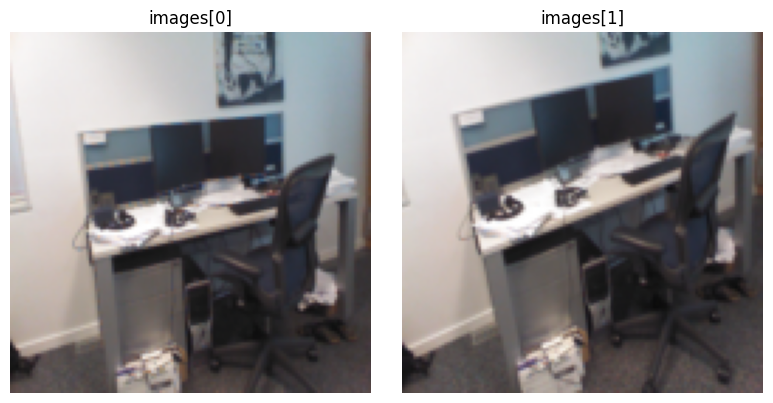


=== 12scenes ===
Sample 0:
  images: tensor (2, 3, 128, 128) torch.float32  min=-2.118 max=2.640
  poses: tensor (2, 4, 4) torch.float32  min=-0.018 max=1.000
  K: tensor (2, 3, 3) torch.float32  min=0.000 max=152.533
  noise: tensor (2, 256) torch.float32  min=0.002 max=1.000
  overlap: tensor () torch.float32  min=0.789 max=0.789

CSV row:
 scene        apt1_kitchen
split               train
seq_a              seq-01
idx_a                 360
seq_b              seq-01
idx_b                 365
overlap          0.789474
ov_a             0.789474
ov_b             0.933333
inliers               266
dist_m           0.019604
angle_deg        1.122393
same_seq             True


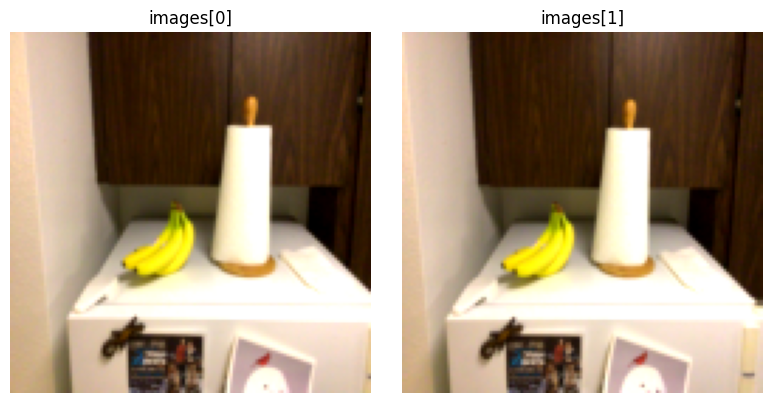


=== arkitscenes ===
Sample 0:
  images: tensor (2, 3, 128, 128) torch.float32  min=-1.804 max=1.891
  poses: tensor (2, 4, 4) torch.float32  min=-0.091 max=1.000
  K: tensor (2, 3, 3) torch.float32  min=0.000 max=142.918
  noise: tensor (2, 256) torch.float32  min=0.001 max=0.999
  overlap: tensor () torch.float32  min=0.556 max=0.556

CSV row:
 scene        41007581
split           train
seq_a        41007581
idx_a         1341509
seq_b        41007581
idx_b         1342009
overlap      0.555556
ov_a         0.578947
ov_b         0.555556
inliers            30
dist_m       0.055956
angle_deg    6.411571
same_seq         True


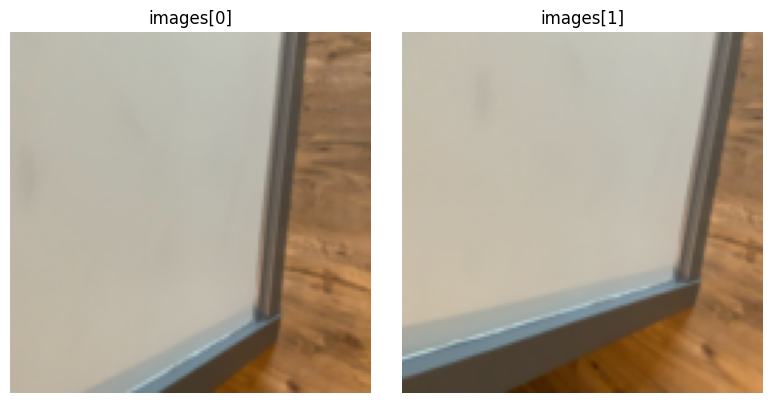

In [ ]:
import matplotlib.pyplot as plt

def unnorm(img):
    # img: (3, H, W) normalized tensor -> (H, W, 3) numpy in [0, 1]
    img = img.detach().cpu() * STD + MEAN
    return img.clamp(0, 1).permute(1, 2, 0).numpy()

def find_images(sample):
    # returns list of (name, (3,H,W) tensor), handles separate views or stacked (2,3,H,W)
    items = sample.items() if isinstance(sample, dict) else enumerate(sample)
    imgs = []
    for k, v in items:
        if torch.is_tensor(v):
            if v.ndim == 3 and v.shape[0] == 3:
                imgs.append((str(k), v))
            elif v.ndim == 4 and v.shape[1] == 3:
                imgs += [(f"{k}[{i}]", v[i]) for i in range(v.shape[0])]
    return imgs

def describe(sample):
    items = sample.items() if isinstance(sample, dict) else enumerate(sample)
    for k, v in items:
        if torch.is_tensor(v):
            print(f"  {k}: tensor {tuple(v.shape)} {v.dtype}  min={v.min():.3f} max={v.max():.3f}")
        else:
            print(f"  {k}: {type(v).__name__} = {v}")

def show_pair(ds, idx, pairs_df=None):
    sample = ds[idx]
    print(f"Sample {idx}:")
    describe(sample)
    if pairs_df is not None:
        print("\nCSV row:\n", pairs_df.iloc[idx].to_string())

    imgs = find_images(sample)
    if not imgs:
        print("\nNo (3,H,W) image tensors found, check the keys above.")
        return
    fig, axes = plt.subplots(1, len(imgs), figsize=(4 * len(imgs), 4))
    axes = np.atleast_1d(axes)
    for ax, (name, img) in zip(axes, imgs):
        ax.imshow(unnorm(img))
        ax.set_title(name)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

# one training pair from each dataset
for name in USE:
    i = next((n for n, p in enumerate(parts["train"]) if p["dataset"] == name), None)
    if i is not None:
        print(f"\n=== {name} ===")
        show_pair(train_parts[i], 0, parts["train"][i]["df"])

Starting the Model

In [ ]:
import torch
import torchvision
import torch.nn as nn

In [ ]:
def pos_embed_2d( grid_size, embed_dim):
    half = embed_dim // 2

    rows = torch.arange(grid_size).repeat_interleave(grid_size).unsqueeze(1)  # (64, 1)
    cols = torch.arange(grid_size).repeat(grid_size).unsqueeze(1)             # (64, 1)

    div_term = torch.exp(torch.arange(0, half, 2) *
                         (-math.log(10000.0) / half))

    pe = torch.zeros(grid_size * grid_size, embed_dim)
    pe[:, 0:half:2] = torch.sin(rows * div_term)
    pe[:, 1:half:2] = torch.cos(rows * div_term)
    pe[:, half::2] = torch.sin(cols * div_term)
    pe[:, half + 1::2] = torch.cos(cols * div_term)
    return pe

In [ ]:
import math

class PatchEmbeddings(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer= nn.Conv2d(3, 192, kernel_size=8, stride=8)
    self.register_buffer("pos_embed", pos_embed_2d(16, 192))

  def forward(self,x):
      #print(f"X at input= {x.shape}") #B,V, 3,128, 128
      B,V,_,_,_= x.shape
      #Folding the first 2 dimensions
      x= x.flatten(0, 1) #B*V, 3, 128, 128
      x= self.layer(x) #B*V, 192, 8,8
      x=x.flatten(-2) #B*V, 192, 64
      x= x.transpose(1,2)

      x+=self.pos_embed

      x = x.reshape(B, V, x.shape[1], x.shape[2])

      return x




In [ ]:
def random_masking(x, noise, mask_ratio):
    """
    Mask one view.
    x:          (B, N, D) tokens of one view
    noise:      (B, N) from the dataloader; smallest values are kept
    mask_ratio: fraction of patches to hide, 0.0 to 1.0
    Returns:
      x_kept:      (B, len_keep, D) visible tokens
      mask:        (B, N) 1 = hidden, 0 = kept, in original patch order
      ids_restore: (B, N) indices to put tokens back in original order
    """
    B, N, D = x.shape
    len_keep = int(round(N * (1 - mask_ratio)))

    ids_shuffle = torch.argsort(noise, dim=1)           # smallest noise first
    ids_restore = torch.argsort(ids_shuffle, dim=1)
    ids_keep = ids_shuffle[:, :len_keep]

    x_kept = torch.gather(x, 1, ids_keep.unsqueeze(-1).expand(-1, -1, D))

    mask = torch.ones(B, N, device=x.device)
    mask[:, :len_keep] = 0
    mask = torch.gather(mask, 1, ids_restore)           # back to original order

    return x_kept, mask, ids_restore


def mask_views(tokens, noise, ratios):
    """
    tokens: (B, V, N, D), noise: (B, V, N), ratios: one mask ratio per view
    Returns a list with one (x_kept, mask, ids_restore) per view.
    """
    return [random_masking(tokens[:, v], noise[:, v], r) for v, r in enumerate(ratios)]

In [ ]:
class Attention(nn.Module):
  def __init__(self, in_f=192, num_heads=3 ):
    super().__init__()
    self.query= nn.Linear(in_f, in_f)
    self.key= nn.Linear(in_f,in_f)
    self.value= nn.Linear(in_f, in_f)
    self.output_layer= nn.Linear(in_f, in_f) #to mix the things learnt by the various heads and get a sinle output that combines all the info
    self.num_heads= num_heads
    self.head_dim= int(in_f//num_heads)

  def forward(self, x):
    q = self.query(x)
    k = self.key(x)
    v = self.value(x)

    #reshaping for different heads. 64 will be divided into 4 heads each of 16 features
    q= q.reshape(x.shape[0], x.shape[1], self.num_heads, self.head_dim)
    k= k.reshape(x.shape[0], x.shape[1], self.num_heads, self.head_dim)
    v= v.reshape(x.shape[0], x.shape[1], self.num_heads, self.head_dim)

    #transposing to 4,49, 16 -> 4 heads each with 49 tokens , each with 16 features
    q= q.transpose(1,2)
    k= k.transpose(1,2)
    v= v.transpose(1,2)

    scores= q @ k.transpose(2,3)
    scores= scores/(self.head_dim**0.5)

    weights= torch.softmax(scores, dim=-1)

    #scores are used to multiply with the value and get information from all the patches accordingly so that the new patches now contain "relevant" info according to the use case
    context_vector= weights @ v #shape= B,4,49, 16

    output= context_vector.transpose(1,2) #B, 49, 4, 16
    output= output.flatten(2) #B, 49, 64
    output= self.output_layer(output)

    return output



In [ ]:
class CrossAttention(nn.Module):
  def __init__(self, in_f=256, num_heads=4):
    super().__init__()
    self.query= nn.Linear(in_f, in_f) #
    self.key= nn.Linear(in_f,in_f)
    self.value= nn.Linear(in_f, in_f)
    self.output_layer= nn.Linear(in_f, in_f) #to mix the things learnt by the various heads and get a sinle output that combines all the info
    self.num_heads= num_heads
    self.head_dim= int(in_f//num_heads)

  def forward(self, v0, v1):
    q = self.query(v1) #B, 64, 256
    k = self.key(v0)
    v = self.value(v0)

    q= q.reshape(v1.shape[0], v1.shape[1], self.num_heads, self.head_dim)
    k= k.reshape(v0.shape[0], v0.shape[1], self.num_heads, self.head_dim)
    v= v.reshape(v0.shape[0], v0.shape[1], self.num_heads, self.head_dim)

    q= q.transpose(1,2)
    k= k.transpose(1,2)
    v= v.transpose(1,2)

    scores= q @ k.transpose(2,3)
    scores= scores/(self.head_dim**0.5)

    weights= torch.softmax(scores, dim=-1)
    context_vector= weights @ v

    output= context_vector.transpose(1,2)
    output= output.flatten(2)
    output= self.output_layer(output)

    return output







In [ ]:
class MLP(nn.Module):
  def __init__(self, in_f):
    super().__init__()
    self.layer1= nn.Linear(in_f, in_f*4)
    self.gelu = nn.GELU(approximate="tanh")
    self.layer2= nn.Linear(in_f*4, in_f)

  def forward(self, x):
    x= self.layer2(self.gelu(self.layer1(x)))
    return x

In [ ]:
class EncoderBlock(nn.Module):
  def __init__(self, in_f, num_heads=3):
    super().__init__()
    self.norm1= nn.LayerNorm(in_f)
    self.attention = Attention(in_f, num_heads)
    self.mlp = MLP(in_f)
    self.norm2= nn.LayerNorm(in_f)

  def forward(self, x):
    x = x + self.attention(self.norm1(x))
    x = x + self.mlp(self.norm2(x))

    return x

In [ ]:
class Encoder(nn.Module):
  def __init__(self, in_f=192, depth=6):
    super().__init__()
    self.patchembeddings= PatchEmbeddings()
    self.block= nn.ModuleList([EncoderBlock(in_f) for _ in range(depth)])
    self.norm= nn.LayerNorm(in_f)

  def forward(self,x, noise,ratios):
    x = self.patchembeddings(x)
    masked = mask_views(x, noise, ratios)
    latents, masks, ids_restores = [], [], []
    for x_kept, mask, ids_restore in masked:
            if x_kept.shape[1] > 0:                    # skip the encoder for a blank view
                for blk in self.block:
                    x_kept = blk(x_kept)               # (B, len_keep, 192), already 3D
                x_kept = self.norm(x_kept)
            latents.append(x_kept)
            masks.append(mask)
            ids_restores.append(ids_restore)

    return latents, masks, ids_restores


In [ ]:
class DecoderBlock(nn.Module):
  def __init__(self,in_f=256, num_heads=4):
    super().__init__()
    self.norm1= nn.LayerNorm(in_f)
    self.selfAttention= Attention(in_f, num_heads)

    self.norm_view= nn.LayerNorm(in_f)
    self.norm_masked=nn.LayerNorm(in_f)
    self.crossAttention = CrossAttention(in_f, num_heads)


    self.mlp = MLP(in_f)
    self.norm2= nn.LayerNorm(in_f)

  def forward(self, v0, v1):

    v1= v1 + self.selfAttention(self.norm1(v1))
    v1= v1 + self.crossAttention(self.norm_view(v0), self.norm_masked(v1))
    v1 = v1 + self.mlp(self.norm2(v1))

    return v1




In [ ]:
class StatsHead(nn.Module):
  def __init__(self, dec_dim=256, hidden=256):
    super().__init__()
    self.layer1= nn.Linear(dec_dim, hidden)
    self.gelu= nn.GELU(approximate="tanh")
    self.layer2= nn.Linear(hidden, 2)

  def forward(self,x):
    return self.layer2(self.gelu(self.layer1(x)))

In [ ]:
class Decoder(nn.Module):
  def __init__(self, enc_dim=192, dec_dim=256, grid_size=16, patch_size=8, num_views=2, depth=8, in_channels=3, num_heads=4):
    super().__init__()
    self.linearLayer= nn.Linear(enc_dim, dec_dim)
    self.mask_token= nn.Parameter(torch.randn(1,1,dec_dim)*0.02)
    self.register_buffer("pos_embed", pos_embed_2d(grid_size, dec_dim).unsqueeze(0))
    self.view_parameter= nn.Parameter(torch.randn(num_views, dec_dim)*0.02)
    self.blocks = nn.ModuleList([DecoderBlock(dec_dim, num_heads) for _ in range(depth)])
    self.norm= nn.LayerNorm(dec_dim)
    self.pred = nn.Linear(dec_dim, patch_size * patch_size * in_channels)
    self.pred_stats = StatsHead(dec_dim)

  def forward(self,latents, ids_restores):
    views = []
    for v, (lat, ids_restore) in enumerate(zip(latents, ids_restores)):
      x = self.linearLayer(lat)                                    # (B, N_visible, 256)
      B, N_visible, D = x.shape
      N = ids_restore.shape[1]                                     # 64

      mask_tokens = self.mask_token.expand(B, N - N_visible, D)    # (B, 64 - N_visible, 128)
      x = torch.cat([x, mask_tokens], dim=1)                       # (B, 64, 128)

      # put every token back in its original patch position
      x = torch.gather(x, 1, ids_restore.unsqueeze(-1).expand(-1, -1, D))

      x = x + self.pos_embed                                       # where in the image, (1, 64, 128)
      x = x + self.view_parameter[v]                               # which view, (128,)
      views.append(x)

    v0= views[0]
    v1= views[1]

    for block in self.blocks:
      v1 = block(v0, v1)

    v1 = self.norm(v1)
    return self.pred(v1), self.pred_stats(v1)




In [ ]:
STATS_WEIGHT = 0.2

class EncoderDecoder(nn.Module):
  def __init__(self, encoder, decoder, patch_size=8, norm_pix_loss=True, stats_weight=STATS_WEIGHT):
    super().__init__()
    self.encoder = encoder
    self.decoder = decoder
    self.patch_size = patch_size
    self.norm_pix_loss = norm_pix_loss
    self.stats_weight = stats_weight
    self.last_losses = {}
    self.last_stats = None

  def patchify(self, imgs):
        """
        imgs: (B, V, C, H, W)  ->  (B, V, num_patches, p*p*C)
        Patches go row by row (left to right, top to bottom), the same order as the conv's tokens.
        Inside each patch: pixel rows, then pixel columns, then the 3 colors.
        """
        B, V, C, H, W = imgs.shape
        p = self.patch_size
        h, w = H // p, W // p
        x = imgs.reshape(B, V, C, h, p, w, p)
        x = x.permute(0, 1, 3, 5, 4, 6, 2)          # (B, V, h, w, p, p, C)
        return x.reshape(B, V, h * w, p * p * C)

  def unpatchify(self, x, C=3):
        """
        x: (B, V, num_patches, p*p*C)  ->  (B, V, C, H, W). Exact reverse of patchify.
        """
        B, V, L, _ = x.shape
        p = self.patch_size
        h = w = int(L ** 0.5)
        x = x.reshape(B, V, h, w, p, p, C)
        x = x.permute(0, 1, 6, 2, 4, 3, 5)          # (B, V, C, h, p, w, p)
        return x.reshape(B, V, C, h * p, w * p)

  def forward_loss(self, imgs, pred, stats, mask):
        target = self.patchify(imgs)[:, 1]                           # (B, N, 192)
        mean = target.mean(dim=-1, keepdim=True)
        var = target.var(dim=-1, keepdim=True)
        if self.norm_pix_loss:
            target = (target - mean) / (var + 1e-6) ** 0.5
        denom = mask.sum().clamp(min=1)

        # 1. pattern loss, exactly as before
        pattern = ((pred.float() - target) ** 2).mean(dim=-1)        # (B, N)
        pattern = (pattern * mask).sum() / denom

        # 2. brightness and contrast loss, hidden patches only
        stats_loss = torch.zeros((), device=imgs.device)
        if self.norm_pix_loss:
            true_mean = mean.squeeze(-1)                             # (B, N)
            true_log_std = 0.5 * torch.log(var.squeeze(-1) + 1e-6)   # (B, N), same std as the normalization
            s = stats.float()
            err = (s[..., 0] - true_mean) ** 2 + (s[..., 1] - true_log_std) ** 2
            stats_loss = (err * mask).sum() / denom

        self.last_losses = {"pattern": pattern.detach(), "stats": stats_loss.detach()}
        return pattern + self.stats_weight * stats_loss

  def forward(self, imgs, noise, ratios):
        latents, masks, ids_restores = self.encoder(imgs, noise, ratios)
        pred, stats = self.decoder(latents, ids_restores)
        mask = masks[1]
        self.last_stats = stats.float().detach()                     # for the display code
        loss = self.forward_loss(imgs, pred, stats, mask)
        return loss, pred, mask


In [ ]:
import math, time, os
import numpy as np
import torch
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = device == "cuda"

# frame 1 (reference) always fully visible, frame 2 (target) hidden at a random ratio per batch
TARGET_MIN, TARGET_MAX = 0.75, 0.95
# work in whole patches: how many target patches stay visible
KEEP_MIN = int(round(NUM_PATCHES * (1 - TARGET_MAX)))   # 3 of 64
KEEP_MAX = int(round(NUM_PATCHES * (1 - TARGET_MIN)))   # 16 of 64

# val and test always use one fixed ratio so numbers are comparable across steps and runs
TARGET_RATIO = 0.9
EVAL_RATIOS = [0.0, TARGET_RATIO]

#TOTAL_STEPS = 1000
TOTAL_STEPS=20000
#WARMUP_STEPS = 100
WARMUP_STEPS=200
VAL_EVERY = 200
LR = 5e-4
MIN_LR_FRAC = 0.05          # cosine decays to 5% of LR
WEIGHT_DECAY = 0.05
GRAD_CLIP = 1.0
RESUME = True

# new name so this run does not resume the old fixed-ratio checkpoint
RUN_NAME = f"7_scenes+12_scenes+arkit_stats_mlp_0.2"
RUN_DIR = f"/content/drive/MyDrive/mae_runs/{RUN_NAME}"
os.makedirs(RUN_DIR, exist_ok=True)
BEST_PATH = os.path.join(RUN_DIR, "best.pt")
LAST_PATH = os.path.join(RUN_DIR, "last.pt")
print(f"device: {device} | run: {RUN_NAME} | target visible patches: {KEEP_MIN} to {KEEP_MAX}")

device: cuda | run: 7_scenes+12_scenes+arkit_stats_mlp_0.2 | target visible patches: 13 to 64


In [ ]:
def lr_lambda(step):
    """Multiplier on LR: linear warmup, then cosine decay to MIN_LR_FRAC."""
    if step < WARMUP_STEPS:
        return (step + 1) / WARMUP_STEPS
    progress = (step - WARMUP_STEPS) / max(1, TOTAL_STEPS - WARMUP_STEPS)
    return MIN_LR_FRAC + (1 - MIN_LR_FRAC) * 0.5 * (1 + math.cos(math.pi * min(progress, 1.0)))

def infinite(loader):
    """Yield batches forever, reshuffling each time the loader runs out."""
    while True:
        for batch in loader:
            yield batch

def to_device(batch):
    return batch["images"].to(device, non_blocking=True), batch["noise"].to(device, non_blocking=True)

def sample_train_ratios(rng):
    """One ratio for the whole batch. Pick how many target patches stay visible, turn it into a ratio."""
    k = int(rng.integers(KEEP_MIN, KEEP_MAX + 1))      # inclusive of KEEP_MAX
    return [0.0, 1.0 - k / NUM_PATCHES]

@torch.no_grad()
def evaluate(model, loader, ratios, return_stats=False):
    model.eval()
    total, total_stats, count = 0.0, 0.0, 0.0
    for batch in loader:
        imgs, noise = to_device(batch)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            _, _, mask = model(imgs, noise, ratios)
        n = mask.sum().item()
        total += model.last_losses["pattern"].item() * n
        total_stats += model.last_losses["stats"].item() * n
        count += n
    pattern = total / max(count, 1)
    return (pattern, total_stats / max(count, 1)) if return_stats else pattern

def per_sample_loss(model, imgs, pred, mask):
    """Loss for each pair separately, averaged over its hidden patches. Returns (B,)."""
    target = model.patchify(imgs)[:, 1]                              # (B, 64, 768), masked view only
    if model.norm_pix_loss:
        mean = target.mean(dim=-1, keepdim=True)
        var = target.var(dim=-1, keepdim=True)
        target = (target - mean) / (var + 1e-6) ** 0.5
    l = ((pred.float() - target) ** 2).mean(dim=-1)                 # (B, 64)
    return (l * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)

def save_ckpt(path, model, opt, sched, scaler, step, best_val, history):
    torch.save({
        "model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
        "scaler": scaler.state_dict(), "step": step, "best_val": best_val, "history": history,
        "config": {"target_range": (TARGET_MIN, TARGET_MAX), "eval_ratios": EVAL_RATIOS,
                   "total_steps": TOTAL_STEPS, "lr": LR},
    }, path)

In [ ]:
model = EncoderDecoder(Encoder(), Decoder(num_heads=4)).to(device)
opt = torch.optim.AdamW(model.parameters(), lr=LR, betas=(0.9, 0.95), weight_decay=WEIGHT_DECAY)
sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

step, best_val = 0, float("inf")
history = {"train": [], "val": [], "ratio": [], "val_stats": []}

if RESUME and os.path.exists(LAST_PATH):
    ck = torch.load(LAST_PATH, map_location=device)
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
    sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
    step, best_val, history = ck["step"], ck["best_val"], ck["history"]
    history.setdefault("ratio", [])
    history.setdefault("val_stats", [])
    print(f"resumed at step {step}, best val {best_val:.4f}")

# seeded by step so a resumed run does not replay the same ratios
rng = np.random.default_rng(step)
data_iter = infinite(train_loader)
model.train()
t0 = time.time()

while step < TOTAL_STEPS:
    imgs, noise = to_device(next(data_iter))
    ratios = sample_train_ratios(rng)

    with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
        loss, _, _ = model(imgs, noise, ratios)

    opt.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    scaler.unscale_(opt)
    torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
    scaler.step(opt)
    scaler.update()
    sched.step()
    step += 1
    history["train"].append((step, model.last_losses["pattern"].item()))
    history["ratio"].append((step, ratios[1]))

    if step % VAL_EVERY == 0 or step == TOTAL_STEPS:
        val, val_stats = evaluate(model, val_loader, EVAL_RATIOS, return_stats=True)
        history["val"].append((step, val))
        history["val_stats"].append((step, val_stats))
        recent = np.mean([l for _, l in history["train"][-VAL_EVERY:]])
        is_best = val < best_val
        if is_best:
            best_val = val
            save_ckpt(BEST_PATH, model, opt, sched, scaler, step, best_val, history)
        save_ckpt(LAST_PATH, model, opt, sched, scaler, step, best_val, history)
        print(f"step {step:5d} | train {recent:.4f} | val@{TARGET_RATIO} {val:.4f} | stats {val_stats:.4f} | "
              f"lr {sched.get_last_lr()[0]:.2e} | {time.time() - t0:.0f}s" + ("  <- best" if is_best else ""))
        model.train()

print(f"done. best val {best_val:.4f}")

resumed at step 14800, best val 0.3335
step 15000 | train 0.2988 | val@0.9 0.3315 | stats 0.1380 | lr 9.59e-05 | 74s  <- best
step 15200 | train 0.3034 | val@0.9 0.3320 | stats 0.1376 | lr 9.06e-05 | 147s
step 15400 | train 0.3057 | val@0.9 0.3304 | stats 0.1375 | lr 8.55e-05 | 219s  <- best
step 15600 | train 0.2990 | val@0.9 0.3292 | stats 0.1359 | lr 8.06e-05 | 292s  <- best
step 15800 | train 0.3006 | val@0.9 0.3291 | stats 0.1360 | lr 7.58e-05 | 366s  <- best
step 16000 | train 0.3028 | val@0.9 0.3282 | stats 0.1351 | lr 7.12e-05 | 439s  <- best
step 16200 | train 0.3000 | val@0.9 0.3280 | stats 0.1353 | lr 6.69e-05 | 512s  <- best
step 16400 | train 0.2972 | val@0.9 0.3274 | stats 0.1348 | lr 6.27e-05 | 585s  <- best
step 16600 | train 0.2996 | val@0.9 0.3263 | stats 0.1339 | lr 5.87e-05 | 658s  <- best
step 16800 | train 0.2988 | val@0.9 0.3258 | stats 0.1337 | lr 5.50e-05 | 732s  <- best
step 17000 | train 0.3001 | val@0.9 0.3255 | stats 0.1336 | lr 5.14e-05 | 805s  <- best
ste

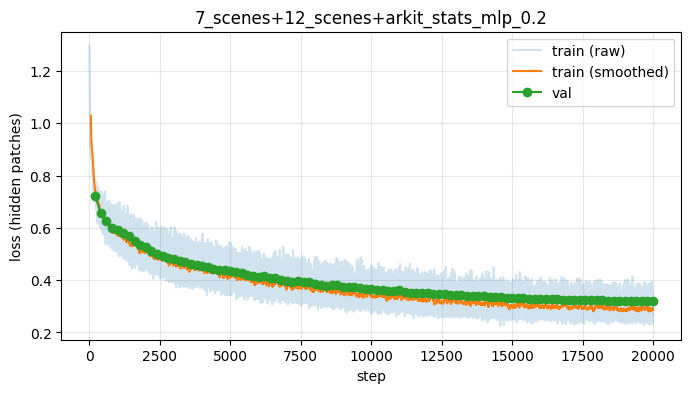

In [ ]:
steps, losses = zip(*history["train"])
smooth = np.convolve(losses, np.ones(50) / 50, mode="valid")
vsteps, vlosses = zip(*history["val"])

plt.figure(figsize=(8, 4))
plt.plot(steps, losses, alpha=0.2, label="train (raw)")
plt.plot(steps[49:], smooth, label="train (smoothed)")
plt.plot(vsteps, vlosses, "o-", label="val")
plt.xlabel("step"); plt.ylabel("loss (hidden patches)")
plt.title(RUN_NAME); plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [ ]:
ck = torch.load(BEST_PATH, map_location=device)
model.load_state_dict(ck["model"])
print(f"loaded best from step {ck['step']} (val {ck['best_val']:.4f})")

# 1. test loss at the fixed eval ratio
test_loss = evaluate(model, test_loader, EVAL_RATIOS)
print(f"\ntest loss at {EVAL_RATIOS}: {test_loss:.4f}")

for scene, loader in test_loaders.items():
    print(f"  {scene}: {evaluate(model, loader, EVAL_RATIOS):.4f}")

# 2. does the reference help? sweep across and past the training range
print("\ntarget ratio | with reference | reference hidden |  gap")
for r in [0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95]:
    with_ref = evaluate(model, test_loader, [0.0, r])
    no_ref = evaluate(model, test_loader, [1.0, r])
    tag = "  (in train range)" if TARGET_MIN <= r <= TARGET_MAX else ""
    print(f"    {r:.2f}     |     {with_ref:.4f}     |      {no_ref:.4f}      | {no_ref - with_ref:.4f}{tag}")

# 3. loss by overlap, at the fixed eval ratio
model.eval()
all_loss, all_ov = [], []
with torch.no_grad():
    for batch in test_loader:
        imgs, noise = to_device(batch)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            _, pred, mask = model(imgs, noise, EVAL_RATIOS)
        all_loss.append(per_sample_loss(model, imgs, pred, mask).cpu())
        all_ov.append(batch["overlap"])
all_loss, all_ov = torch.cat(all_loss), torch.cat(all_ov)

print("\noverlap bin | pairs | mean loss")
bins = [(0.5, 0.6), (0.6, 0.7), (0.7, 0.8)]
for n, (lo, hi) in enumerate(bins):
    last = n == len(bins) - 1
    sel = (all_ov >= lo) & ((all_ov <= hi) if last else (all_ov < hi))
    if sel.any():
        print(f" {lo:.1f} to {hi:.1f}  | {int(sel.sum()):5d} | {all_loss[sel].mean():.4f}")

loaded best from step 20000 (val 0.3200)

test loss at [0.0, 0.9]: 0.3376
  office: 0.3069
  redkitchen: 0.3398
  chess: 0.4166
  pumpkin: 0.2696
  fire: 0.3825
  stairs: 0.2693
  12scenes: 0.3321
  arkitscenes: 0.3471

target ratio | with reference | reference hidden |  gap
    0.50     |     0.2273     |      0.4807      | 0.2535
    0.60     |     0.2414     |      0.5261      | 0.2847
    0.70     |     0.2593     |      0.5875      | 0.3282
    0.75     |     0.2715     |      0.6312      | 0.3597  (in train range)
    0.80     |     0.2867     |      0.6868      | 0.4001  (in train range)
    0.85     |     0.3077     |      0.7601      | 0.4524  (in train range)
    0.90     |     0.3376     |      0.8513      | 0.5137  (in train range)
    0.95     |     0.4090     |      0.9892      | 0.5803  (in train range)

overlap bin | pairs | mean loss
 0.5 to 0.6  | 14089 | 0.3764
 0.6 to 0.7  |  7979 | 0.3182
 0.7 to 0.8  |  5265 | 0.2631


In [ ]:
@torch.no_grad()
def show_reconstructions(model, ds, ratios, idxs, title=""):
    model.eval()
    items = [ds[i] for i in idxs]
    imgs = torch.stack([it["images"] for it in items]).to(device)
    noise = torch.stack([it["noise"] for it in items]).to(device)
    _, pred, mask = model(imgs, noise, ratios)                       # pred (B, 64, 768), mask (B, 64)

    target = model.patchify(imgs)[:, 1]                              # (B, 64, 768), masked view only
    pred = pred.float()
    if model.norm_pix_loss:                                          # undo per-patch normalization
        mean = target.mean(dim=-1, keepdim=True)
        var = target.var(dim=-1, keepdim=True)
        pred = pred * (var + 1e-6) ** 0.5 + mean

    m = mask.unsqueeze(-1)                                           # (B, 64, 1)
    recon_patches = pred * m + target * (1 - m)                      # real visible patches pasted in
    # unpatchify expects a view dim, so add a size-1 one back
    recon = model.unpatchify(recon_patches.unsqueeze(1)).cpu()                  # (B, 1, 3, H, W)
    hidden = model.unpatchify(m.expand_as(target).float().unsqueeze(1)).cpu()   # (B, 1, 3, H, W), 1 where hidden
    gt = imgs.cpu()                                                  # (B, 2, 3, H, W), still both views

    def to_np(x):
        return (x * STD + MEAN).clamp(0, 1).permute(1, 2, 0).numpy()

    fig, ax = plt.subplots(len(idxs), 4, figsize=(12, 3 * len(idxs)), squeeze=False)
    for r in range(len(idxs)):
        h = hidden[r, 0].permute(1, 2, 0).numpy()
        masked_target = to_np(gt[r, 1]) * (1 - h) + 0.5 * h         # hidden patches shown gray
        panels = [(to_np(gt[r, 0]), "reference"),
                  (masked_target, f"target input ({ratios[1]:.0%} hidden)"),
                  (to_np(recon[r, 0]), "reconstruction"),
                  (to_np(gt[r, 1]), "ground truth")]
        for c, (img, name) in enumerate(panels):
            ax[r, c].imshow(img); ax[r, c].axis("off")
            if r == 0:
                ax[r, c].set_title(name)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

idxs = list(range(0, len(test_ds), max(1, len(test_ds) // 6)))[:6]
show_reconstructions(model, test_ds, EVAL_RATIOS, idxs, f"test: with reference ({TARGET_RATIO:.0%} hidden)")
show_reconstructions(model, test_ds, [1.0, TARGET_RATIO], idxs, "test: reference hidden")

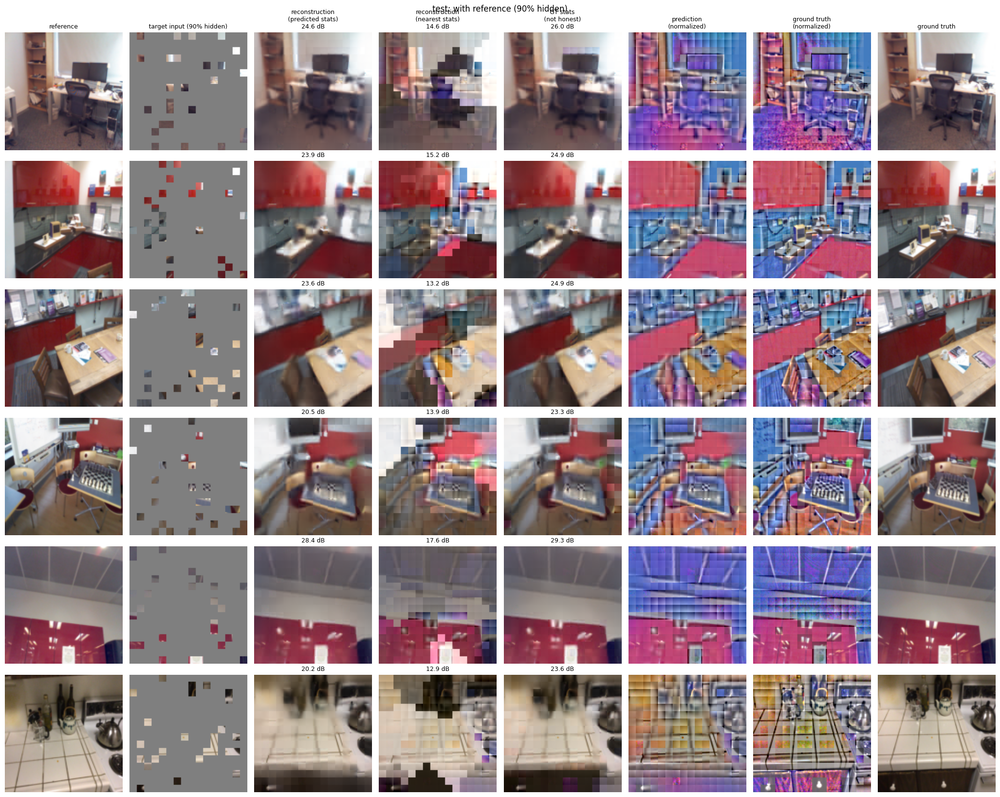

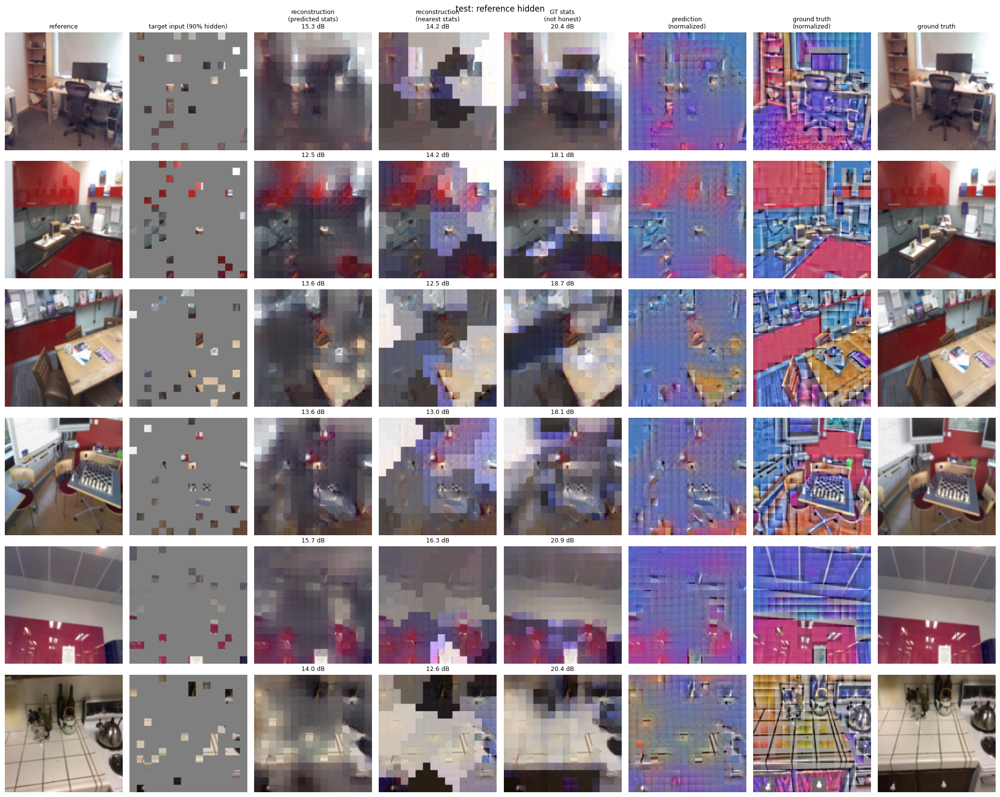

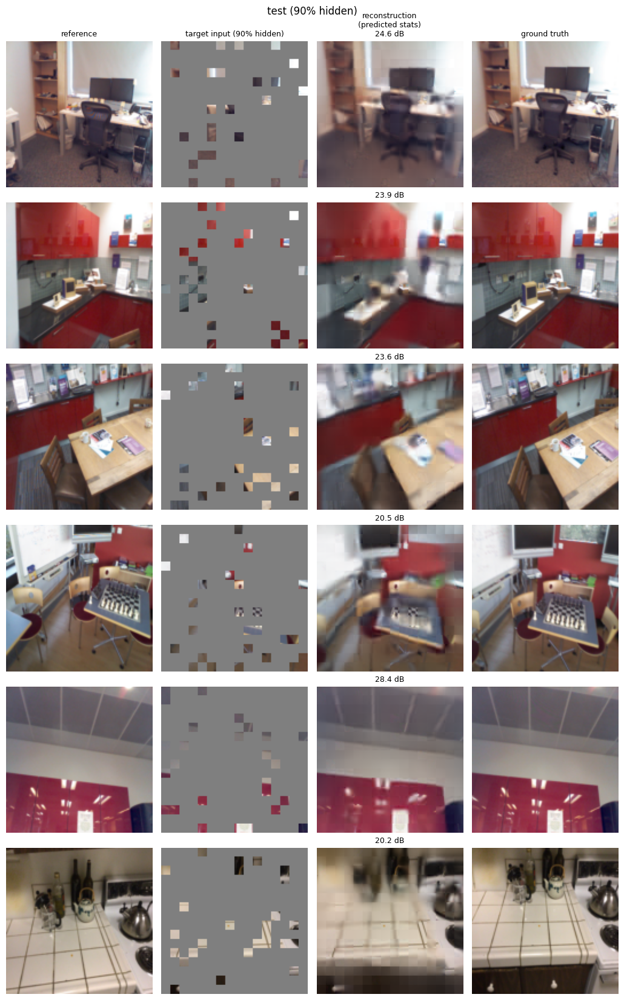

office       {'predicted': 21.49, 'honest': 13.28, 'leaky': 24.04}
redkitchen   {'predicted': 21.67, 'honest': 13.98, 'leaky': 23.51}
chess        {'predicted': 20.12, 'honest': 14.85, 'leaky': 21.7}
pumpkin      {'predicted': 22.17, 'honest': 15.46, 'leaky': 23.86}
fire         {'predicted': 20.69, 'honest': 14.2, 'leaky': 22.49}
stairs       {'predicted': 24.34, 'honest': 17.57, 'leaky': 25.61}
12scenes     {'predicted': 22.27, 'honest': 14.76, 'leaky': 24.56}
arkitscenes  {'predicted': 21.75, 'honest': 14.97, 'leaky': 24.22}


In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt

def patch_stats(patches):
    """patches: (B, N, D). Per-patch mean and spread, computed exactly like norm_pix_loss."""
    mean = patches.mean(dim=-1, keepdim=True)
    std = (patches.var(dim=-1, keepdim=True) + 1e-6) ** 0.5
    return mean, std

def honest_stats(target, ref, mask, mode="nearest"):
    """
    Brightness (mean) and contrast (std) for every target patch, using only what the model saw.
    target, ref: (B, N, D) patches in normalized image space. mask: (B, N), 1 = hidden.
    "nearest": a hidden patch takes the stats of the closest visible target patch on the grid.
    "global":  a hidden patch takes the average stats of all visible target patches.
    Visible patches keep their own stats (the model saw them).
    If no target patch is visible, falls back to the reference image's average stats.
    """
    B, N, _ = target.shape
    g = int(N ** 0.5)
    t_mean, t_std = patch_stats(target)
    r_mean, r_std = patch_stats(ref)
    mean, std = t_mean.clone(), t_std.clone()

    idx = torch.arange(N, device=target.device)
    coords = torch.stack([idx // g, idx % g], dim=1).float()      # (N, 2) row, col of each patch

    for b in range(B):
        vis = mask[b] == 0
        hid = ~vis
        if hid.sum() == 0:
            continue
        if vis.sum() == 0:
            mean[b, hid] = r_mean[b].mean()
            std[b, hid] = r_std[b].mean()
        elif mode == "global":
            mean[b, hid] = t_mean[b, vis].mean()
            std[b, hid] = t_std[b, vis].mean()
        else:
            nearest = torch.cdist(coords[hid], coords[vis]).argmin(dim=1)   # closest visible patch
            mean[b, hid] = t_mean[b, vis][nearest]
            std[b, hid] = t_std[b, vis][nearest]
    return mean, std

def build_views(model, imgs, pred, mask, mode="nearest", stats=None):
    """
    Returns a dict of (B, 3, H, W) images:
      "predicted": hidden patches use the model's own brightness and contrast (needs stats)
      "honest":    hidden patches borrow brightness and contrast from visible target patches
      "leaky":     hidden patches use the ground truth brightness and contrast (not honest)
      "pred_z", "gt_z": normalized pattern only (what the pattern loss compares)
      "hidden":    1 where the target patch was hidden
    Visible target patches are always the real ones, since the model saw them.
    """
    patches = model.patchify(imgs)                                # (B, 2, N, D)
    ref, target = patches[:, 0], patches[:, 1]
    m = mask.unsqueeze(-1).float()                                # (B, N, 1), 1 = hidden
    out = {"hidden": m.expand_as(target)}

    if model.norm_pix_loss:
        h_mean, h_std = honest_stats(target, ref, mask, mode)
        g_mean, g_std = patch_stats(target)
        target_z = (target - g_mean) / g_std
        if stats is not None:
            p_mean = stats[..., 0:1].float()
            p_std = stats[..., 1:2].float().exp()
            out["predicted"] = (pred * p_std + p_mean) * m + target * (1 - m)
        out["honest"] = (pred * h_std + h_mean) * m + target * (1 - m)
        out["leaky"] = (pred * g_std + g_mean) * m + target * (1 - m)
        out["pred_z"] = pred * m + target_z * (1 - m)
        out["gt_z"] = target_z
    else:
        out["predicted"] = pred * m + target * (1 - m)            # model predicts real pixels, nothing to borrow

    unp = lambda x: model.unpatchify(x.unsqueeze(1))[:, 0]
    return {k: unp(v) for k, v in out.items()}

def to_pixels(x):
    """(B, 3, H, W) normalized image -> pixel values in [0, 1]."""
    return (x * STD.to(x.device) + MEAN.to(x.device)).clamp(0, 1)

def z_to_display(x):
    """Normalized patches (mean 0, spread 1) -> [0, 1] for viewing. 0 shows as mid gray."""
    return (x * 0.2 + 0.5).clamp(0, 1)

def hidden_psnr(recon, gt, hidden):
    """PSNR per image over hidden pixels only. All inputs (B, 3, H, W), pixels in [0, 1]."""
    mse = (((recon - gt) ** 2) * hidden).sum(dim=(1, 2, 3)) / hidden.sum(dim=(1, 2, 3)).clamp(min=1)
    return 10 * torch.log10(1.0 / mse.clamp(min=1e-10))

@torch.no_grad()
def show_reconstructions(model, ds, ratios, idxs, title="", mode="nearest", show_extra=True):
    """
    One row per pair. Columns:
      reference | target input | reconstruction (predicted stats) |
      [reconstruction (nearest stats) | GT stats (not honest) | prediction normalized | ground truth normalized] |
      ground truth
    The bracketed columns are shown when show_extra=True.
    """
    model.eval()
    items = [ds[i] for i in idxs]
    imgs = torch.stack([it["images"] for it in items]).to(device)
    noise = torch.stack([it["noise"] for it in items]).to(device)
    _, pred, mask = model(imgs, noise, ratios)
    v = build_views(model, imgs, pred.float(), mask, mode, stats=model.last_stats)

    ref_px = to_pixels(imgs[:, 0])
    gt_px = to_pixels(imgs[:, 1])
    hidden = v["hidden"]
    masked_px = gt_px * (1 - hidden) + 0.5 * hidden               # hidden patches shown gray

    cols = [("reference", ref_px, None),
            (f"target input ({ratios[1]:.0%} hidden)", masked_px, None)]
    if "predicted" in v:
        pred_px = to_pixels(v["predicted"])
        cols.append(("reconstruction\n(predicted stats)", pred_px, hidden_psnr(pred_px, gt_px, hidden)))
    if show_extra and "honest" in v:
        honest_px = to_pixels(v["honest"])
        leaky_px = to_pixels(v["leaky"])
        cols += [(f"reconstruction\n({mode} stats)", honest_px, hidden_psnr(honest_px, gt_px, hidden)),
                 ("GT stats\n(not honest)", leaky_px, hidden_psnr(leaky_px, gt_px, hidden)),
                 ("prediction\n(normalized)", z_to_display(v["pred_z"]), None),
                 ("ground truth\n(normalized)", z_to_display(v["gt_z"]), None)]
    cols.append(("ground truth", gt_px, None))

    n = len(idxs)
    fig, ax = plt.subplots(n, len(cols), figsize=(2.6 * len(cols), 2.8 * n), squeeze=False)
    for r in range(n):
        for c, (name, img, psnr) in enumerate(cols):
            ax[r, c].imshow(img[r].permute(1, 2, 0).cpu().numpy())
            ax[r, c].axis("off")
            label = name if r == 0 else ""
            if psnr is not None:
                label = (label + "\n" if label else "") + f"{psnr[r].item():.1f} dB"
            ax[r, c].set_title(label, fontsize=9)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

@torch.no_grad()
def hidden_psnr_over_loader(model, loader, ratios, mode="nearest", max_batches=None):
    """Mean hidden-pixel PSNR over a loader for each reconstruction type."""
    model.eval()
    sums, count = {}, 0
    for n, batch in enumerate(loader):
        if max_batches is not None and n >= max_batches:
            break
        imgs, noise = to_device(batch)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            _, pred, mask = model(imgs, noise, ratios)
        v = build_views(model, imgs, pred.float(), mask, mode, stats=model.last_stats)
        gt_px = to_pixels(imgs[:, 1])
        for k in ("predicted", "honest", "leaky"):
            if k in v:
                sums[k] = sums.get(k, 0.0) + hidden_psnr(to_pixels(v[k]), gt_px, v["hidden"]).sum().item()
        count += imgs.shape[0]
    return {k: round(s / max(count, 1), 2) for k, s in sums.items()}

# ---- usage ----
idxs = list(range(0, len(test_ds), max(1, len(test_ds) // 6)))[:6]

# full comparison: all reconstruction types side by side
show_reconstructions(model, test_ds, EVAL_RATIOS, idxs,
                     f"test: with reference ({TARGET_RATIO:.0%} hidden)")

# what the model does without the reference
show_reconstructions(model, test_ds, [1.0, TARGET_RATIO], idxs,
                     "test: reference hidden")

# clean figure for the README: only the model's own output
show_reconstructions(model, test_ds, EVAL_RATIOS, idxs,
                     f"test ({TARGET_RATIO:.0%} hidden)", show_extra=False)

# PSNR per test group (predicted vs borrowed vs ground truth brightness)
for name in test_loaders:
    print(f"{name:12s}", hidden_psnr_over_loader(model, test_loaders[name], EVAL_RATIOS, max_batches=20))